In [19]:
%pip install torch --index-url https://download.pytorch.org/whl/cpu
%pip install scikit-learn pandas matplotlib seaborn kagglehub

Looking in indexes: https://download.pytorch.org/whl/cpu
   ---------------------------------------- 0.0/126.6 MB ? eta -:--:--
   - -------------------------------------- 3.9/126.6 MB 22.3 MB/s eta 0:00:06
   --- ------------------------------------ 10.7/126.6 MB 27.1 MB/s eta 0:00:05
   ----- ---------------------------------- 17.8/126.6 MB 29.0 MB/s eta 0:00:04
   ------- -------------------------------- 24.9/126.6 MB 30.2 MB/s eta 0:00:04
   ---------- ----------------------------- 31.7/126.6 MB 30.5 MB/s eta 0:00:04
   ------------ --------------------------- 39.1/126.6 MB 31.5 MB/s eta 0:00:03
   -------------- ------------------------- 46.1/126.6 MB 31.6 MB/s eta 0:00:03
   ---------------- ----------------------- 53.0/126.6 MB 31.9 MB/s eta 0:00:03
   ------------------- -------------------- 60.3/126.6 MB 32.0 MB/s eta 0:00:03
   --------------------- ------------------ 68.2/126.6 MB 32.4 MB/s eta 0:00:02
   ----------------------- ---------------- 75.2/126.6 MB 32.4 MB/s eta 0


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


# 03 – Stress Tests (Milestone 3, Section 1.3)
**Project:** AI-Based Credit Card Fraud Detection (unsupervised anomaly detection) | **Course:** INSE 6450

This notebook stress-tests the **final autoencoder** from `02_model_training.ipynb` (and the Isolation Forest
baseline for comparison) under four families of stress:

| Family | What is simulated (tabular analogue of the image/NLP corruption) |
|---|---|
| **A. Corrupted inputs** | A1 Gaussian **noise** on numeric features · A2 **blur** = precision loss (rounded amounts, coarse GPS, floored timestamps) · A3 random **masking** of fields (mean-imputed) · A4 **token dropout / swap** of the merchant-category token |
| **B. Partial feature loss** | a whole feature group is unavailable for every transaction (e.g. card-history service down); imputed model vs. a fallback model retrained without it |
| **C. OOD samples** | C1 natural temporal drift (month by month) · C2 synthetic covariate shift of legitimate traffic (price inflation, travel, older customers) · C3 injected out-of-range records |
| **D. Class rarity** | D1 test fraud prevalence sweep · D2 rare fraud sub-types (per category / amount band) · D3 fraud contamination of the training data |

**Metrics reported for every scenario** (same metric family as Milestone 2): PR-AUC (primary), ROC-AUC,
Precision / Recall / F1 at the **1% alert budget** (top 1% of scores flagged), and, at a **fixed threshold**
(validation 99th percentile, the deployable operating point), the alert rate and recall.
Random corruptions are repeated with 3 seeds and reported as mean ± std.

The preprocessing, split and model configuration are identical to notebook 02. If `outputs/models/autoencoder.pt`
from notebook 02 exists it is loaded; otherwise the selected configuration is retrained with the same seed.

## 1. Imports and settings (same as notebook 02)

In [20]:
import os, sys, shutil, subprocess, time, json, random, copy, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
                             recall_score, f1_score, accuracy_score)

sns.set_theme(style="darkgrid")
plt.rcParams["figure.figsize"] = (7, 5)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

SEED = 42
MAX_EPOCHS_FINAL = 25
PATIENCE = 3
MIN_DELTA = 1e-5
EARLY_STOP_ON = "val_loss"
BATCH_SIZE = 2048
FLAG_RATE = 0.01
VAL_FRACTION = 0.20

BEST_CFG = {"hidden": (16,), "bottleneck": 8, "lr": 0.003, "weight_decay": 1e-05}   # selected in notebook 02
IF_CFG = {"n_estimators": 100, "max_samples": 256}                                    # selected in notebook 02
STRESS_SEEDS = [42, 43, 44]          # repeats for every random corruption

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_seed()

for d in ("outputs/figures", "outputs/results", "outputs/models"):
    os.makedirs(d, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("python", platform.python_version(), "| torch", torch.__version__, "| device", device,
      "| cpu cores", os.cpu_count())

python 3.13.7 | torch 2.15.0+cpu | device cpu | cpu cores 8


## 2. Data (download if needed) and the exact preprocessing of notebook 02

In [21]:
if not (os.path.exists("fraudTrain.csv") and os.path.exists("fraudTest.csv")):
    try:
        import kagglehub
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
        import kagglehub
    path = Path(kagglehub.dataset_download("kartik2112/fraud-detection"))
    for name in ("fraudTrain.csv", "fraudTest.csv"):
        shutil.copy(next(path.rglob(name)), name)

KEEP = ["trans_date_trans_time", "cc_num", "category", "amt", "gender", "lat", "long", "city_pop",
        "dob", "trans_num", "merch_lat", "merch_long", "is_fraud"]          # only columns the pipeline uses
train_df = pd.read_csv("fraudTrain.csv", usecols=KEEP)
test_df = pd.read_csv("fraudTest.csv", usecols=KEEP)

def clean(df):
    df = df.copy()
    df["trans_date_trans_time"] = pd.to_datetime(df["trans_date_trans_time"])
    df["dob"] = pd.to_datetime(df["dob"])
    df = df.drop_duplicates(subset="trans_num").dropna()
    return df.sort_values("trans_date_trans_time").reset_index(drop=True)

def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))

def build_features(df):
    ts = df["trans_date_trans_time"]
    out = pd.DataFrame(index=df.index)
    out["hour"] = ts.dt.hour
    out["day_of_week"] = ts.dt.dayofweek
    out["month"] = ts.dt.month
    out["is_weekend"] = (out["day_of_week"] >= 5).astype(int)
    out["is_night"] = ((out["hour"] >= 22) | (out["hour"] <= 3)).astype(int)
    out["age"] = (ts - df["dob"]).dt.days / 365.25
    out["gender_male"] = (df["gender"] == "M").astype(int)
    out["log_amt"] = np.log1p(df["amt"])
    out["log_city_pop"] = np.log1p(df["city_pop"])
    out["distance_km"] = haversine_km(df["lat"], df["long"], df["merch_lat"], df["merch_long"])
    out["category"] = df["category"].values
    out["is_fraud"] = df["is_fraud"].values
    return out

def card_history_features(train_c, test_c):
    """Causal per-card features: use only transactions that happened BEFORE the current one."""
    tr = train_c.assign(_split="train", _rid=np.arange(len(train_c)))
    te = test_c.assign(_split="test", _rid=np.arange(len(test_c)))
    full = (pd.concat([tr, te], ignore_index=True)
              .sort_values("trans_date_trans_time", kind="stable").reset_index(drop=True))
    g = full.groupby("cc_num", sort=False)
    gap_hours = g["trans_date_trans_time"].diff().dt.total_seconds() / 3600
    n_prev = g.cumcount()
    past_mean = (g["amt"].cumsum() - full["amt"]) / n_prev.where(n_prev > 0)
    hist = pd.DataFrame({
        "log_hours_since_last": np.log1p(gap_hours.fillna(24.0)),
        "amt_vs_card_mean": (np.log1p(full["amt"]) - np.log1p(past_mean)).fillna(0.0),
        "_split": full["_split"], "_rid": full["_rid"],
    })
    parts = []
    for name in ("train", "test"):
        h = hist[hist["_split"] == name].sort_values("_rid").drop(columns=["_split", "_rid"])
        parts.append(h.reset_index(drop=True))
    return parts

train_clean, test_clean = clean(train_df), clean(test_df)
del train_df, test_df
train_feat, test_feat = build_features(train_clean), build_features(test_clean)
train_hist, test_hist = card_history_features(train_clean, test_clean)
train_feat = pd.concat([train_feat, train_hist], axis=1)
test_feat = pd.concat([test_feat, test_hist], axis=1)

split_idx = int(len(train_feat) * (1 - VAL_FRACTION))
tr_feat = train_feat.iloc[:split_idx].reset_index(drop=True)
va_feat = train_feat.iloc[split_idx:].reset_index(drop=True)
te_feat = test_feat.reset_index(drop=True)

tr_enc = pd.get_dummies(tr_feat, columns=["category"], prefix="cat", dtype=int)
SCALE_COLS = ["hour", "day_of_week", "month", "age", "log_amt", "log_city_pop", "distance_km",
              "log_hours_since_last", "amt_vs_card_mean"]
scaler = StandardScaler().fit(tr_enc[SCALE_COLS])
ENC_COLS = list(tr_enc.columns)
FEATURES = [c for c in ENC_COLS if c != "is_fraud"]
CAT_COLS = [c for c in FEATURES if c.startswith("cat_")]
CATEGORIES = [c[4:] for c in CAT_COLS]

def encode(feat_df):
    """One-hot + scaling exactly as in notebook 02 (scaler fit on the training split only)."""
    enc = pd.get_dummies(feat_df, columns=["category"], prefix="cat", dtype=int).reindex(
        columns=ENC_COLS, fill_value=0)
    enc[SCALE_COLS] = scaler.transform(enc[SCALE_COLS])
    return enc[FEATURES].to_numpy(np.float32), enc["is_fraud"].to_numpy(int)

X_tr, y_tr = encode(tr_feat)
X_va, y_va = encode(va_feat)
X_te, y_te = encode(te_feat)
del tr_enc

def prepare_test(test_raw):
    """Re-run the full pipeline on a (possibly corrupted) raw test frame -> (X, y)."""
    f = build_features(test_raw)
    _, h = card_history_features(train_clean, test_raw)
    return encode(pd.concat([f, h], axis=1))

FI = {c: i for i, c in enumerate(FEATURES)}
CONT_IDX = [FI[c] for c in SCALE_COLS]
CAT_IDX = [FI[c] for c in CAT_COLS]
TRAIN_MEAN = X_tr.mean(axis=0)          # imputation value for every column (0 for scaled columns)
print("Features:", len(FEATURES), "| X_train", X_tr.shape, "| X_val", X_va.shape, "| X_test", X_te.shape)
print("Test fraud:", y_te.sum(), f"({y_te.mean():.3%})")

C:\Users\marya\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|███████████████████████████████████████████████████████████████████████████████| 202M/202M [00:07<00:00, 29.2MB/s]

Extracting files...


Features: 26 | X_train (1037340, 26) | X_val (259335, 26) | X_test (555719, 26)
Test fraud: 2145 (0.386%)


## 3. Models: final autoencoder (main) and Isolation Forest (baseline)

In [22]:
class AutoEncoder(nn.Module):
    def __init__(self, n_in, hidden=(32,), bottleneck=8):
        super().__init__()
        enc_dims = [n_in, *hidden, bottleneck]
        dec_dims = [bottleneck, *reversed(hidden), n_in]
        def mlp(dims):
            layers = []
            for i in range(len(dims) - 1):
                layers.append(nn.Linear(dims[i], dims[i + 1]))
                if i < len(dims) - 2:
                    layers.append(nn.ReLU())
            return nn.Sequential(*layers)
        self.encoder, self.decoder = mlp(enc_dims), mlp(dec_dims)

    def forward(self, x):
        return self.decoder(self.encoder(x))


@torch.no_grad()
def recon_error(model, X, bs=65536):
    model.eval()
    if isinstance(X, np.ndarray):
        X = torch.from_numpy(X).to(device)
    out = []
    for i in range(0, len(X), bs):
        xb = X[i:i + bs]
        out.append(((model(xb) - xb) ** 2).mean(dim=1).cpu())
    return torch.cat(out).numpy()


def train_ae(X_train, X_val, y_val, cfg, max_epochs, patience=PATIENCE, seed=SEED):
    """Same training loop as notebook 02 (early stopping on validation reconstruction loss)."""
    set_seed(seed)
    model = AutoEncoder(X_train.shape[1], cfg["hidden"], cfg["bottleneck"]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    Xt = torch.from_numpy(X_train).to(device)
    Xv = torch.from_numpy(X_val).to(device)
    n = len(Xt)
    best_score, best_state, best_epoch, wait = float("inf"), None, 0, 0
    t_start = time.time()
    for epoch in range(1, max_epochs + 1):
        model.train()
        perm = torch.randperm(n, device=device)
        for i in range(0, n, BATCH_SIZE):
            xb = Xt[perm[i:i + BATCH_SIZE]]
            loss = ((model(xb) - xb) ** 2).mean(dim=1).mean()
            opt.zero_grad(); loss.backward(); opt.step()
        val_loss = float(recon_error(model, Xv).mean())
        if val_loss < best_score - MIN_DELTA:
            best_score, best_epoch, wait = val_loss, epoch, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    return model, {"epochs_run": epoch, "best_epoch": best_epoch, "train_time_s": time.time() - t_start}


AE_PATH = "outputs/models/autoencoder.pt"
ae = AutoEncoder(len(FEATURES), BEST_CFG["hidden"], BEST_CFG["bottleneck"]).to(device)
if os.path.exists(AE_PATH):
    ae.load_state_dict(torch.load(AE_PATH, map_location=device))
    print("Loaded autoencoder from notebook 02:", AE_PATH)
else:
    ae, info = train_ae(X_tr, X_va, y_va, BEST_CFG, MAX_EPOCHS_FINAL)
    torch.save(ae.state_dict(), AE_PATH)
    print("Retrained autoencoder with the selected configuration:", info)
ae.eval()

t0 = time.time()
iso = IsolationForest(**IF_CFG, contamination="auto", random_state=SEED, n_jobs=-1).fit(X_tr)
print(f"Isolation Forest fitted in {time.time() - t0:.1f} s")

def score(model_name, X):
    return recon_error(ae, X) if model_name == "Autoencoder" else -iso.score_samples(X)

MODELS = ["Autoencoder", "Isolation Forest"]
# Fixed (deployable) threshold = 99th percentile of the VALIDATION scores, as in notebook 02
THR = {m: float(np.quantile(score(m, X_va), 1 - FLAG_RATE)) for m in MODELS}
CLEAN_SCORES = {m: score(m, X_te) for m in MODELS}
print("Fixed thresholds (val p99):", {k: round(v, 4) for k, v in THR.items()})

Retrained autoencoder with the selected configuration: {'epochs_run': 14, 'best_epoch': 11, 'train_time_s': 16.835180521011353}
Isolation Forest fitted in 0.5 s
Fixed thresholds (val p99): {'Autoencoder': 0.0665, 'Isolation Forest': 0.5111}


## 4. Metric helpers and the clean reference

In [23]:
def stress_metrics(y, s, model_name):
    """Primary metrics at the 1% alert budget + fixed-threshold alert rate / recall."""
    thr_b = np.quantile(s, 1 - FLAG_RATE)
    pred_b = s >= thr_b
    pred_f = s >= THR[model_name]
    return {
        "PR-AUC": average_precision_score(y, s),
        "ROC-AUC": roc_auc_score(y, s),
        "Precision@1%": precision_score(y, pred_b, zero_division=0),
        "Recall@1%": recall_score(y, pred_b, zero_division=0),
        "F1@1%": f1_score(y, pred_b, zero_division=0),
        "Alert rate (fixed thr)": pred_f.mean(),
        "Recall (fixed thr)": recall_score(y, pred_f, zero_division=0),
    }

METRIC_COLS = ["PR-AUC", "ROC-AUC", "Precision@1%", "Recall@1%", "F1@1%", "Alert rate (fixed thr)", "Recall (fixed thr)"]
ROWS = []          # every evaluation lands here: family, test, level, model, seed, metrics

def log(family, test, level, model_name, y, s, seed=None, **extra):
    r = {"family": family, "test": test, "level": level, "model": model_name, "seed": seed,
         **stress_metrics(y, s, model_name), **extra}
    ROWS.append(r)
    return r

for m in MODELS:
    log("0. Clean", "clean test set", "none", m, y_te, CLEAN_SCORES[m])
clean_df = pd.DataFrame(ROWS)[["model"] + METRIC_COLS]
CLEAN = clean_df.set_index("model")
clean_df.round(4)

,model,PR-AUC,ROC-AUC,Precision@1%,Recall@1%,F1@1%,Alert rate (fixed thr),Recall (fixed thr)
0,Autoencoder,0.2250,0.6871,0.1582,0.4098,0.2282,0.0087,0.4000
1,Isolation Forest,0.1347,0.8967,0.1375,0.3562,0.1984,0.0136,0.3991


## 5. A. Corrupted inputs
Tabular analogues of the image/NLP corruptions in the brief:
* **A1 Noise** – additive Gaussian noise N(0, σ²) on the 9 standardized numeric features (σ in units of the training std).
* **A2 Blur** – loss of precision at the source, applied to the *raw* data and pushed through the full pipeline:
  amounts rounded, merchant GPS coordinates truncated, timestamps floored (like a blurred image keeps the scene but loses detail).
* **A3 Masking** – each field of each transaction is missing with probability p and replaced by the training mean (mean imputation fallback).
  Fields = 9 numeric + 3 binary + the category block.
* **A4 Token dropout / swap** – the merchant-category token is dropped (all-zero one-hot = unmapped code) or swapped for a random wrong category.

In [24]:
FIELDS = {c: [FI[c]] for c in SCALE_COLS + ["is_weekend", "is_night", "gender_male"]}
FIELDS["category"] = CAT_IDX

def add_noise(X, sigma, rng):
    Xc = X.copy()
    Xc[:, CONT_IDX] += rng.normal(0, sigma, size=(len(X), len(CONT_IDX))).astype(np.float32)
    return Xc

def mask_fields(X, p, rng):
    Xc = X.copy()
    for cols in FIELDS.values():
        rows = rng.random(len(X)) < p
        Xc[np.ix_(rows, cols)] = TRAIN_MEAN[cols]
    return Xc

def drop_category(X, p, rng):
    Xc = X.copy()
    rows = rng.random(len(X)) < p
    Xc[np.ix_(rows, CAT_IDX)] = 0.0
    return Xc

def swap_category(X, p, rng):
    Xc = X.copy()
    rows = np.where(rng.random(len(X)) < p)[0]
    cur = Xc[rows][:, CAT_IDX].argmax(axis=1)
    new = (cur + rng.integers(1, len(CAT_IDX), size=len(rows))) % len(CAT_IDX)   # always a different category
    block = np.zeros((len(rows), len(CAT_IDX)), np.float32)
    block[np.arange(len(rows)), new] = 1.0
    Xc[np.ix_(rows, CAT_IDX)] = block
    return Xc

RANDOM_CORRUPTIONS = [
    ("A1 Gaussian noise", "σ", [0.1, 0.25, 0.5, 1.0], add_noise),
    ("A3 Random field masking", "p", [0.05, 0.10, 0.25, 0.50], mask_fields),
    ("A4 Category token dropout", "p", [0.10, 0.25, 0.50, 1.00], drop_category),
    ("A4 Category token swap", "p", [0.10, 0.25, 0.50], swap_category),
]
t0 = time.time()
for test, sym, levels, fn in RANDOM_CORRUPTIONS:
    for lvl in levels:
        for sd in STRESS_SEEDS:
            Xc = fn(X_te, lvl, np.random.default_rng(sd))
            for m in MODELS:
                log("A. Corrupted inputs", test, f"{sym}={lvl}", m, y_te, score(m, Xc), seed=sd, severity=lvl)
print(f"A1/A3/A4 done in {time.time() - t0:.0f} s")

A1/A3/A4 done in 325 s


In [25]:
BLUR_LEVELS = {   # amount step ($), decimals kept on merchant lat/long, timestamp floor
    "light":  dict(amt_step=1,  geo_dec=2, time_floor="h"),     # ~1 km GPS precision
    "medium": dict(amt_step=10, geo_dec=1, time_floor="h"),     # ~11 km
    "heavy":  dict(amt_step=50, geo_dec=0, time_floor="6h"),    # ~111 km, 6-hour time buckets
}
def blur_raw(df, amt_step, geo_dec, time_floor):
    d = df.copy()
    d["amt"] = np.maximum(np.round(d["amt"] / amt_step) * amt_step, 1.0)
    d["merch_lat"], d["merch_long"] = d["merch_lat"].round(geo_dec), d["merch_long"].round(geo_dec)
    d["trans_date_trans_time"] = d["trans_date_trans_time"].dt.floor(time_floor)
    return d

for i, (name, kw) in enumerate(BLUR_LEVELS.items(), 1):
    Xb, _ = prepare_test(blur_raw(test_clean, **kw))
    for m in MODELS:
        log("A. Corrupted inputs", "A2 Blur (precision loss)", name, m, y_te, score(m, Xb), severity=i)
    print("blur", name, "done")

blur light done
blur medium done
blur heavy done


**Which component drives the damage?** (diagnostics, autoencoder and Isolation Forest)
* A2b – the three parts of the *heavy* blur applied one at a time.
* A3b – a single field masked (p = 0.10, mean-imputed) at a time, plus the share of the 1% alert queue taken by masked rows.

In [26]:
for part, kw in [("amount to $50 only", dict(amt_step=50, geo_dec=6, time_floor="s")),
                 ("GPS to 0 decimals only", dict(amt_step=0.01, geo_dec=0, time_floor="s")),
                 ("time to 6 h only", dict(amt_step=0.01, geo_dec=6, time_floor="6h"))]:
    Xb, _ = prepare_test(blur_raw(test_clean, **kw))
    for m in MODELS:
        log("A. Corrupted inputs (diagnostic)", "A2b heavy-blur component", part, m, y_te, score(m, Xb))
a3b = []
for fname, cols in FIELDS.items():
    rng = np.random.default_rng(SEED)
    Xc = X_te.copy()
    rows = rng.random(len(X_te)) < 0.10
    Xc[np.ix_(rows, cols)] = TRAIN_MEAN[cols]
    for m in MODELS:
        s = score(m, Xc)
        flag = s >= np.quantile(s, 1 - FLAG_RATE)
        log("A. Corrupted inputs (diagnostic)", "A3b single field masked (p=0.10)", fname, m, y_te, s,
            **{"share of alerts that are masked rows": float(rows[flag].mean())})
diag = pd.DataFrame([r for r in ROWS if r["family"] == "A. Corrupted inputs (diagnostic)"])
diag[["test", "level", "model", "PR-AUC", "Recall@1%", "Alert rate (fixed thr)", "share of alerts that are masked rows"]].round(4)

,test,level,model,PR-AUC,Recall@1%,Alert rate (fixed thr),share of alerts that are masked rows
0,A2b heavy-blur component,amount to $50 only,Autoencoder,0.2007,0.3972,0.0109,NaN
1,A2b heavy-blur component,amount to $50 only,Isolation Forest,0.0591,0.2168,0.0467,NaN
2,A2b heavy-blur component,GPS to 0 decimals only,Autoencoder,0.1383,0.3911,0.0111,NaN
3,A2b heavy-blur component,GPS to 0 decimals only,Isolation Forest,0.1326,0.3562,0.0166,NaN
4,A2b heavy-blur component,time to 6 h only,Autoencoder,0.1084,0.2145,0.0087,NaN
5,A2b heavy-blur component,time to 6 h only,Isolation Forest,0.0328,0.1441,0.0214,NaN
6,A3b single field masked (p=0.10),hour,Autoencoder,0.0652,0.0942,0.0311,0.9852
7,A3b single field masked (p=0.10),hour,Isolation Forest,0.1306,0.3566,0.0129,0.0405
8,A3b single field masked (p=0.10),day_of_week,Autoencoder,0.2006,0.3907,0.0122,0.3588
9,A3b single field masked (p=0.10),day_of_week,Isolation Forest,0.1353,0.3580,0.0135,0.0820


In [27]:
def summarize(df, keys=("family", "test", "level", "model")):
    """mean ± std over seeds (std is 0 / NaN for deterministic scenarios)."""
    g = df.groupby(list(keys), sort=False)[METRIC_COLS]
    out = g.mean()
    sd = g.std()
    for c in METRIC_COLS:
        out[c + " std"] = sd[c]
    return out.reset_index()

def pm(df, cols=("PR-AUC", "Recall@1%", "Precision@1%", "Alert rate (fixed thr)")):
    """Pretty table: mean ± std strings."""
    t = df[["test", "level", "model"]].copy()
    for c in cols:
        t[c] = [f"{a:.4f}" if (np.isnan(b) or b == 0) else f"{a:.4f} ± {b:.4f}" for a, b in zip(df[c], df[c + " std"])]
    return t

res_A = summarize(pd.DataFrame([r for r in ROWS if r["family"] == "A. Corrupted inputs"]))
pm(res_A[res_A.model == "Autoencoder"])

,test,level,model,PR-AUC,Recall@1%,Precision@1%,Alert rate (fixed thr)
0,A1 Gaussian noise,σ=0.1,Autoencoder,0.2065 ± 0.0018,0.3969 ± 0.0027,0.1532 ± 0.0011,0.0119 ± 0.0001
2,A1 Gaussian noise,σ=0.25,Autoencoder,0.0929 ± 0.0013,0.2216 ± 0.0027,0.0855 ± 0.0010,0.0563 ± 0.0002
4,A1 Gaussian noise,σ=0.5,Autoencoder,0.0116 ± 0.0002,0.0499 ± 0.0017,0.0193 ± 0.0006,0.3233 ± 0.0003
6,A1 Gaussian noise,σ=1.0,Autoencoder,0.0049 ± 0.0001,0.0149 ± 0.0008,0.0058 ± 0.0003,0.7644 ± 0.0004
8,A3 Random field masking,p=0.05,Autoencoder,0.0286 ± 0.0016,0.1041 ± 0.0050,0.0402 ± 0.0019,0.0531 ± 0.0001
10,A3 Random field masking,p=0.1,Autoencoder,0.0325 ± 0.0026,0.1280 ± 0.0044,0.0494 ± 0.0017,0.0902 ± 0.0005
12,A3 Random field masking,p=0.25,Autoencoder,0.0449 ± 0.0035,0.1910 ± 0.0108,0.0737 ± 0.0042,0.1603 ± 0.0007
14,A3 Random field masking,p=0.5,Autoencoder,0.0528 ± 0.0031,0.2364 ± 0.0081,0.0912 ± 0.0031,0.1694 ± 0.0003
16,A4 Category token dropout,p=0.1,Autoencoder,0.2093 ± 0.0002,0.3810 ± 0.0015,0.1471 ± 0.0006,0.0079 ± 0.0000
18,A4 Category token dropout,p=0.25,Autoencoder,0.1891 ± 0.0056,0.3375 ± 0.0063,0.1303 ± 0.0024,0.0066 ± 0.0000


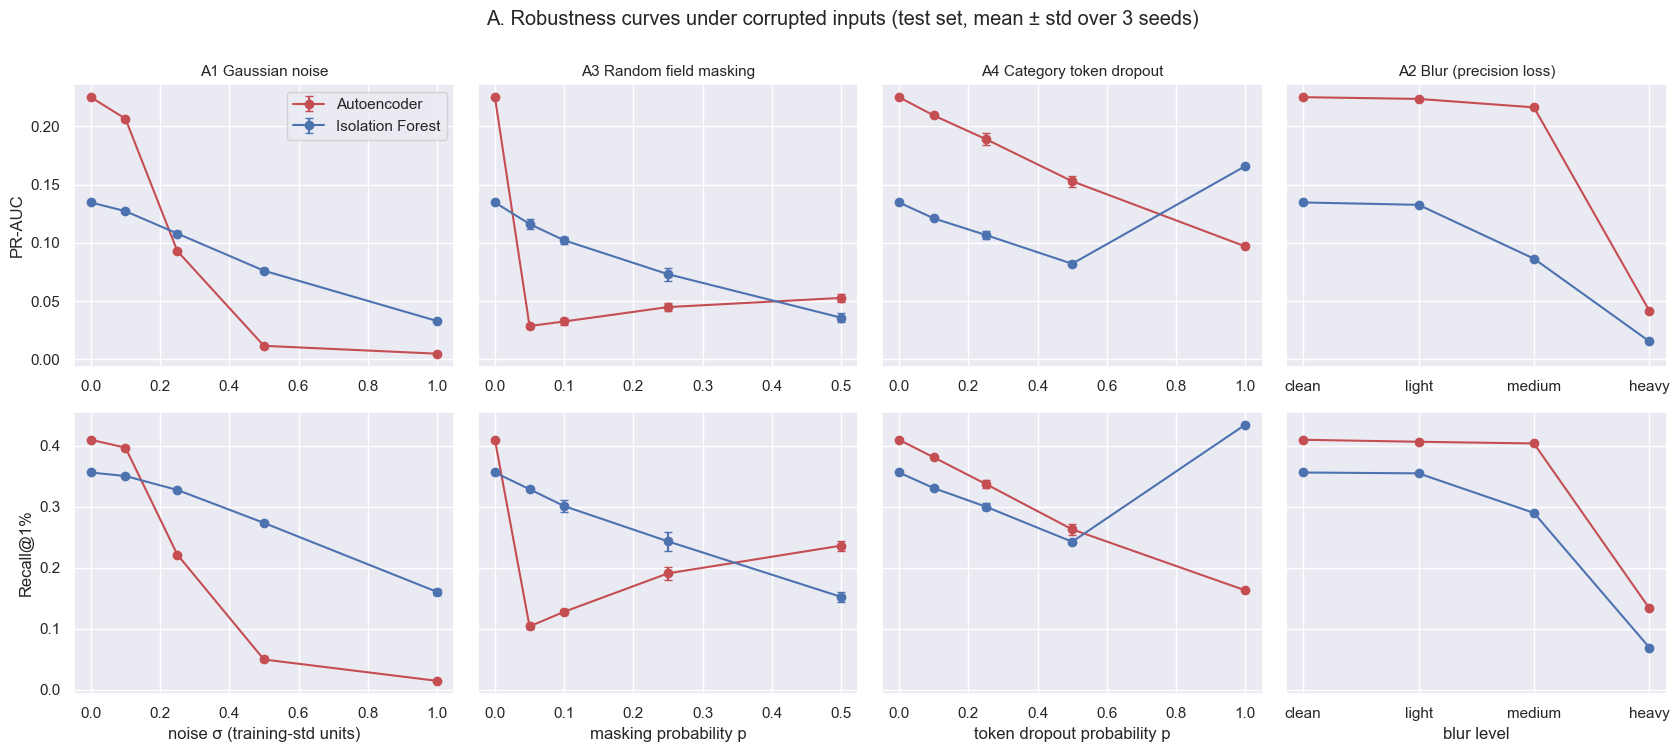

In [28]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5), sharey="row")
curves = [("A1 Gaussian noise", "noise σ (training-std units)"), ("A3 Random field masking", "masking probability p"),
          ("A4 Category token dropout", "token dropout probability p"), ("A2 Blur (precision loss)", "blur level")]
colors = {"Autoencoder": "#c44e52", "Isolation Forest": "#4c72b0"}
raw_A = pd.DataFrame([r for r in ROWS if r["family"] == "A. Corrupted inputs"])
for j, (test, xl) in enumerate(curves):
    for i, met in enumerate(["PR-AUC", "Recall@1%"]):
        ax = axes[i, j]
        for m in MODELS:
            sub = raw_A[(raw_A.test == test) & (raw_A.model == m)].groupby("severity")[met].agg(["mean", "std"]).reset_index()
            xs = np.r_[0, sub["severity"]]
            ys = np.r_[CLEAN.loc[m, met], sub["mean"]]
            es = np.r_[0, sub["std"].fillna(0)]
            ax.errorbar(xs, ys, yerr=es, marker="o", capsize=3, label=m, color=colors[m])
        if test.startswith("A2"):
            ax.set_xticks([0, 1, 2, 3]); ax.set_xticklabels(["clean", "light", "medium", "heavy"])
        ax.set_title(test if i == 0 else "", fontsize=11)
        ax.set_xlabel(xl if i == 1 else "")
        if j == 0:
            ax.set_ylabel(met)
axes[0, 0].legend()
plt.suptitle("A. Robustness curves under corrupted inputs (test set, mean ± std over 3 seeds)", y=1.0)
plt.tight_layout()
plt.savefig("outputs/figures/stress_A_corruption_curves.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. B. Partial feature loss
A whole feature group is unavailable for **every** transaction (upstream outage). Two ways the system can respond:
1. **Impute** the missing group with its training mean and keep the deployed model (no retraining).
2. **Fallback model**: an autoencoder retrained (same configuration and seed) on the remaining features only.

In [ ]:
FEATURE_GROUPS = {
    "card history (history service down)": ["log_hours_since_last", "amt_vs_card_mean"],
    "amount (amt, amt_vs_card_mean)": ["log_amt", "amt_vs_card_mean"],
    "geolocation (distance_km)": ["distance_km"],
    "time (hour, day, month, weekend, night)": ["hour", "day_of_week", "month", "is_weekend", "is_night"],
    "customer profile (age, gender, city_pop)": ["age", "gender_male", "log_city_pop"],
    "merchant category (one-hot)": CAT_COLS,
}
fallback_rows = []
for gname, cols in FEATURE_GROUPS.items():
    idx = [FI[c] for c in cols]
    Xm = X_te.copy()
    Xm[:, idx] = TRAIN_MEAN[idx]
    for m in MODELS:
        log("B. Partial feature loss", gname, "imputed (deployed model)", m, y_te, score(m, Xm))
    keep = [i for i in range(len(FEATURES)) if i not in idx]
    fb, info = train_ae(X_tr[:, keep], X_va[:, keep], y_va, BEST_CFG, MAX_EPOCHS_FINAL)
    s_fb = recon_error(fb, X_te[:, keep])
    thr_fb = np.quantile(recon_error(fb, X_va[:, keep]), 1 - FLAG_RATE)
    r = log("B. Partial feature loss", gname, "fallback AE retrained without group", "Autoencoder", y_te, s_fb)
    # fixed-threshold metrics must use the fallback model's own validation threshold
    r["Alert rate (fixed thr)"] = float((s_fb >= thr_fb).mean())
    r["Recall (fixed thr)"] = recall_score(y_te, s_fb >= thr_fb)
    print(f"{gname}: fallback trained in {info['train_time_s']:.0f} s")

res_B = summarize(pd.DataFrame([r for r in ROWS if r["family"] == "B. Partial feature loss"]))
res_B[["test", "level", "model", "PR-AUC", "ROC-AUC", "Recall@1%", "Precision@1%", "Alert rate (fixed thr)"]].round(4)

card history (history service down): fallback trained in 40 s
amount (amt, amt_vs_card_mean): fallback trained in 95 s
geolocation (distance_km): fallback trained in 198 s
time (hour, day, month, weekend, night): fallback trained in 86 s
customer profile (age, gender, city_pop): fallback trained in 70 s


In [ ]:
bAE = res_B[res_B.model == "Autoencoder"]
groups = list(FEATURE_GROUPS)
imp = bAE[bAE.level.str.startswith("imputed")].set_index("test").loc[groups, "PR-AUC"]
fbk = bAE[bAE.level.str.startswith("fallback")].set_index("test").loc[groups, "PR-AUC"]
fig, ax = plt.subplots(figsize=(9, 4.8))
yy = np.arange(len(groups))
ax.barh(yy - 0.2, imp, 0.4, label="imputed, deployed model", color="#dd8452")
ax.barh(yy + 0.2, fbk, 0.4, label="fallback AE retrained without group", color="#55a868")
ax.axvline(CLEAN.loc["Autoencoder", "PR-AUC"], color="k", ls="--", label="clean (all features)")
for k in range(len(groups)):
    ax.text(imp.iloc[k], k - 0.2, f" {imp.iloc[k]:.3f}", va="center", fontsize=8)
    ax.text(fbk.iloc[k], k + 0.2, f" {fbk.iloc[k]:.3f}", va="center", fontsize=8)
ax.set_yticks(yy); ax.set_yticklabels(groups); ax.invert_yaxis()
ax.set_xlabel("Test PR-AUC (autoencoder)"); ax.set_title("B. Partial feature loss: impute vs. fallback model")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig("outputs/figures/stress_B_feature_loss.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. C. Out-of-distribution samples
**C1 Natural temporal drift.** The model is trained on Jan 2019 – Mar 2020; the test set (Jun – Dec 2020) is already
out-of-time. We score it month by month: validation period vs. each test month.

In [ ]:
months = test_clean["trans_date_trans_time"].dt.to_period("M").astype(str).to_numpy()
for m in MODELS:
    log("C. OOD samples", "C1 temporal drift", "validation (Mar-Jun 2020)", m, y_va, score(m, X_va))
    for mo in sorted(set(months)):
        sel = months == mo
        log("C. OOD samples", "C1 temporal drift", mo, m, y_te[sel], CLEAN_SCORES[m][sel],
            fraud_rate=y_te[sel].mean(), n=int(sel.sum()))
res_C1 = pd.DataFrame([r for r in ROWS if r["test"] == "C1 temporal drift"])
res_C1[["level", "model", "n", "fraud_rate"] + METRIC_COLS].round(4)

**C2 Synthetic covariate shift of the population (benign OOD).** Labels are unchanged; only legitimate behaviour shifts:
price inflation (all amounts × k), customers transacting farther from home (merchant location moved 1–2° north), and an
older customer base (+15 years). Applied to the raw data and pushed through the full pipeline.

In [ ]:
def shift_amount(df, k):
    d = df.copy(); d["amt"] = d["amt"] * k; return d
def shift_geo(df, deg):
    d = df.copy(); d["merch_lat"] = d["merch_lat"] + deg; return d
def shift_age(df, years):
    d = df.copy(); d["dob"] = d["dob"] - pd.DateOffset(years=years); return d

SHIFTS = [("C2 amount inflation", f"×{k}", shift_amount, k, k) for k in (1.25, 1.5, 2.0)] + \
         [("C2 merchant farther away", f"+{d}° lat", shift_geo, d, d) for d in (1.0, 2.0)] + \
         [("C2 older customers", "+15 years", shift_age, 15, 15)]
for test, lvl, fn, arg, sev in SHIFTS:
    Xs, _ = prepare_test(fn(test_clean, arg))
    for m in MODELS:
        log("C. OOD samples", test, lvl, m, y_te, score(m, Xs), severity=sev)
    print(test, lvl, "done")
res_C2 = summarize(pd.DataFrame([r for r in ROWS if r["test"].startswith("C2")]))
res_C2[["test", "level", "model"] + METRIC_COLS].round(4)

**C3 Injected out-of-range records.** 1% of legitimate test transactions are replaced by an OOD version
(they stay labelled legitimate). We measure (i) how many OOD records the model flags (**OOD flag rate**) and
(ii) how much fraud recall is lost because OOD records consume the alert budget.
* amount × 100 (beyond the training max), merchant on another continent (~6,000 km), customer age ≈ 120,
  and a corrupted feature vector (every numeric feature at ±5–10 σ: sensor/ETL garbage).

In [ ]:
def inject(kind, rng, frac=0.01):
    legit = np.where(y_te == 0)[0]
    idx = np.sort(rng.choice(legit, size=int(frac * len(y_te)), replace=False))
    if kind == "garbage":
        X = X_te.copy()
        X[np.ix_(idx, CONT_IDX)] = (rng.uniform(5, 10, (len(idx), len(CONT_IDX))) *
                                    rng.choice([-1, 1], (len(idx), len(CONT_IDX)))).astype(np.float32)
        return X, idx
    d = test_clean.copy()
    if kind == "amount x100":
        d.loc[idx, "amt"] = d.loc[idx, "amt"] * 100
    elif kind == "merchant abroad":
        d.loc[idx, "merch_lat"], d.loc[idx, "merch_long"] = 48.85, 2.35          # Paris
    elif kind == "age 120":
        d.loc[idx, "dob"] = d.loc[idx, "trans_date_trans_time"] - pd.DateOffset(years=120)
    X, _ = prepare_test(d)
    return X, idx

ood_rows = []
for kind in ["amount x100", "merchant abroad", "age 120", "garbage"]:
    Xo, idx = inject(kind, np.random.default_rng(SEED))
    is_ood = np.zeros(len(y_te), bool); is_ood[idx] = True
    for m in MODELS:
        s = score(m, Xo)
        thr_b = np.quantile(s, 1 - FLAG_RATE)
        r = log("C. OOD samples", "C3 injected OOD (1% of rows)", kind, m, y_te, s,
                **{"OOD flagged @1% budget": float((s[is_ood] >= thr_b).mean()),
                   "OOD flagged (fixed thr)": float((s[is_ood] >= THR[m]).mean()),
                   "share of alerts that are OOD": float(is_ood[s >= thr_b].mean()),
                   "median score OOD / clean legit": float(np.median(s[is_ood]) / np.median(CLEAN_SCORES[m][y_te == 0]))})
    print(kind, "done")
res_C3 = pd.DataFrame([r for r in ROWS if r["test"].startswith("C3")])
res_C3[["level", "model", "PR-AUC", "Recall@1%", "OOD flagged @1% budget", "OOD flagged (fixed thr)",
        "share of alerts that are OOD", "median score OOD / clean legit"]].round(4)

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
# (a) monthly drift
c1 = res_C1[res_C1.model == "Autoencoder"]
ax = axes[0]
ax.plot(c1["level"], c1["PR-AUC"], marker="o", color="#c44e52", label="PR-AUC")
ax.plot(c1["level"], c1["Recall@1%"], marker="s", color="#8172b3", label="Recall@1%")
ax.set_xticks(range(len(c1))); ax.set_xticklabels([l.replace("validation (Mar-Jun 2020)", "val") for l in c1["level"]], rotation=45)
ax2 = ax.twinx(); ax2.bar(range(len(c1)), c1["Alert rate (fixed thr)"] * 100, alpha=0.25, color="gray"); ax2.set_ylabel("alert rate at fixed thr (%)")
ax2.grid(False)
ax.set_title("C1 temporal drift (autoencoder)"); ax.legend(loc="upper left", fontsize=8)
# (b) covariate shift: fixed-threshold alert rate
ax = axes[1]
c2 = res_C2[res_C2.model == "Autoencoder"]
short = {"C2 amount inflation": "amount", "C2 merchant farther away": "merchant", "C2 older customers": "age"}
lab = [f"{short[t]}\n{l}" for t, l in zip(c2["test"], c2["level"])]
ax.bar(range(len(c2)), c2["Alert rate (fixed thr)"] * 100, color="#dd8452")
ax.axhline(CLEAN.loc["Autoencoder", "Alert rate (fixed thr)"] * 100, color="k", ls="--", label="clean")
ax.set_xticks(range(len(c2))); ax.set_xticklabels(lab, fontsize=8)
ax.set_ylabel("alert rate at fixed thr (%)"); ax.set_title("C2 covariate shift: alert volume (autoencoder)"); ax.legend()
# (c) score distribution of injected OOD
ax = axes[2]
s_cl = CLEAN_SCORES["Autoencoder"]
ax.hist(np.log10(s_cl[y_te == 0] + 1e-9), bins=80, density=True, alpha=0.5, label="legitimate (clean)")
ax.hist(np.log10(s_cl[y_te == 1] + 1e-9), bins=80, density=True, alpha=0.5, label="fraud (clean)")
for kind, col in [("amount x100", "#937860"), ("merchant abroad", "#da8bc3"), ("garbage", "#8c8c8c")]:
    Xo, idx = inject(kind, np.random.default_rng(SEED))
    ax.hist(np.log10(recon_error(ae, Xo[idx]) + 1e-9), bins=60, density=True, histtype="step", lw=1.8, label=f"injected: {kind}", color=col)
ax.axvline(np.log10(THR["Autoencoder"]), color="k", ls="--", label="fixed threshold")
ax.set_xlabel("log10(reconstruction error)"); ax.set_title("C3 injected OOD vs. in-distribution scores"); ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig("outputs/figures/stress_C_ood.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. D. Class rarity scenarios
**D1 Test prevalence sweep.** The test set is resampled to different fraud rates (fraud rows subsampled to make
fraud rarer; legitimate rows subsampled to make it more common). 20 resamples per level → mean and 95% interval.
Scores are fixed (the model is not retrained), so any change is due to prevalence alone.

In [ ]:
PREVALENCES = [0.02, 0.01, None, 0.001, 0.0005, 0.0002]       # None = native test rate (0.386%)
N_RESAMPLES = 20
fr_idx, lg_idx = np.where(y_te == 1)[0], np.where(y_te == 0)[0]
d1_rows = []
for prev in PREVALENCES:
    for b in range(N_RESAMPLES):
        rng = np.random.default_rng(1000 + b)
        if prev is None:
            sel = rng.choice(len(y_te), len(y_te), replace=True)          # bootstrap of the native set
        elif prev < y_te.mean():
            n_f = max(1, int(round(prev * len(lg_idx) / (1 - prev))))
            sel = np.r_[lg_idx, rng.choice(fr_idx, n_f, replace=False)]
        else:
            n_l = int(round(len(fr_idx) * (1 - prev) / prev))
            sel = np.r_[rng.choice(lg_idx, n_l, replace=False), fr_idx]
        for m in MODELS:
            r = stress_metrics(y_te[sel], CLEAN_SCORES[m][sel], m)
            d1_rows.append({"prevalence": y_te[sel].mean(), "target": "native" if prev is None else prev,
                            "model": m, "n_fraud": int(y_te[sel].sum()), **r})
d1 = pd.DataFrame(d1_rows)
q = lambda p: (lambda x: np.quantile(x, p))
res_D1 = d1.groupby(["target", "model"], sort=False).agg(
    prevalence=("prevalence", "mean"), n_fraud=("n_fraud", "mean"),
    PR_AUC=("PR-AUC", "mean"), PR_AUC_lo=("PR-AUC", q(0.025)), PR_AUC_hi=("PR-AUC", q(0.975)),
    ROC_AUC=("ROC-AUC", "mean"), Precision_1=("Precision@1%", "mean"), Recall_1=("Recall@1%", "mean"),
    Recall_1_lo=("Recall@1%", q(0.025)), Recall_1_hi=("Recall@1%", q(0.975))).reset_index()
for _, r in res_D1.iterrows():
    ROWS.append({"family": "D. Class rarity", "test": "D1 test prevalence sweep", "level": f"fraud rate {r.prevalence:.3%}",
                 "model": r.model, "PR-AUC": r.PR_AUC, "ROC-AUC": r.ROC_AUC, "Precision@1%": r.Precision_1,
                 "Recall@1%": r.Recall_1, "PR-AUC 95% CI": f"[{r.PR_AUC_lo:.4f}, {r.PR_AUC_hi:.4f}]"})
res_D1.round(4)

**D2 Rare fraud sub-types.** Fraud recall at the 1% budget broken down by merchant category and by amount band,
next to how many fraud examples of that kind exist in the training split. Small, low-amount fraud patterns are rare
*and* look normal, which is where an unsupervised detector is expected to fail.

In [ ]:
cat_te = te_feat["category"].to_numpy()
amt_te = test_clean["amt"].to_numpy()
cat_tr_fraud = tr_feat.loc[tr_feat.is_fraud == 1, "category"].value_counts()
d2_rows = []
for m in MODELS:
    s = CLEAN_SCORES[m]
    flag = s >= np.quantile(s, 1 - FLAG_RATE)
    for c in CATEGORIES:
        sel = (cat_te == c) & (y_te == 1)
        d2_rows.append({"model": m, "group": "category", "value": c, "train fraud": int(cat_tr_fraud.get(c, 0)),
                        "test fraud": int(sel.sum()), "Recall@1%": flag[sel].mean()})
    bands = [(0, 50), (50, 200), (200, 500), (500, 1000), (1000, np.inf)]
    amt_tr = train_clean["amt"].iloc[:split_idx].to_numpy()
    for lo, hi in bands:
        sel = (amt_te >= lo) & (amt_te < hi) & (y_te == 1)
        n_tr = int(((amt_tr >= lo) & (amt_tr < hi) & (y_tr == 1)).sum())
        d2_rows.append({"model": m, "group": "amount band", "value": f"${lo:g}–{hi:g}".replace("inf", "∞"),
                        "train fraud": n_tr, "test fraud": int(sel.sum()), "Recall@1%": flag[sel].mean()})
res_D2 = pd.DataFrame(d2_rows)
res_D2_w = res_D2.pivot_table(index=["group", "value", "train fraud", "test fraud"], columns="model",
                              values="Recall@1%", sort=False).reset_index()
res_D2_w.round(3)

**D3 Fraud contamination of the training data.** The autoencoder is unsupervised and trained on *all* transactions,
so fraud hidden in training is learned as "normal". We retrain (same configuration and seed) with the training fraud
rate set to 0% (legitimate only), native (0.575%), 2% and 5% (fraud rows over-sampled), and evaluate on the clean test set.

In [ ]:
tr_f, tr_l = np.where(y_tr == 1)[0], np.where(y_tr == 0)[0]
for name, rate in [("0% (legitimate only)", 0.0), ("native 0.575%", None), ("2%", 0.02), ("5%", 0.05)]:
    if rate is None:
        model_d3, s_va3 = ae, score("Autoencoder", X_va)
    else:
        rng = np.random.default_rng(SEED)
        n_f = int(round(rate * len(tr_l) / (1 - rate)))
        sel = np.r_[tr_l, rng.choice(tr_f, n_f, replace=True)] if n_f else tr_l
        model_d3, _ = train_ae(X_tr[np.sort(sel)], X_va, y_va, BEST_CFG, MAX_EPOCHS_FINAL)
        s_va3 = recon_error(model_d3, X_va)
    s3 = recon_error(model_d3, X_te)
    thr3 = np.quantile(s_va3, 1 - FLAG_RATE)
    r = log("D. Class rarity", "D3 training fraud contamination", name, "Autoencoder", y_te, s3)
    r["Alert rate (fixed thr)"] = float((s3 >= thr3).mean()); r["Recall (fixed thr)"] = recall_score(y_te, s3 >= thr3)
    print(name, "done")
res_D3 = pd.DataFrame([r for r in ROWS if r["test"].startswith("D3")])
res_D3[["level"] + METRIC_COLS].round(4)

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
ax = axes[0]
for m in MODELS:
    sub = res_D1[res_D1.model == m].sort_values("prevalence")
    ax.plot(sub.prevalence * 100, sub.PR_AUC, marker="o", color=colors[m], label=f"{m} PR-AUC")
    ax.fill_between(sub.prevalence * 100, sub.PR_AUC_lo, sub.PR_AUC_hi, color=colors[m], alpha=0.2)
    ax.plot(sub.prevalence * 100, sub.Precision_1, marker="s", ls="--", color=colors[m], label=f"{m} Precision@1%")
ax.set_xscale("log"); ax.set_xlabel("test fraud rate (%) – log scale"); ax.set_ylabel("metric")
ax.set_title("D1 prevalence sweep (95% interval shaded)"); ax.legend(fontsize=7)
ax = axes[1]
cat = res_D2[(res_D2.group == "category") & (res_D2.model == "Autoencoder")].sort_values("train fraud")
ax.scatter(cat["train fraud"], cat["Recall@1%"], color="#c44e52")
for _, r in cat.iterrows():
    if r["Recall@1%"] > 0.05 or r["value"] in ("grocery_pos", "health_fitness"):
        ax.annotate(r["value"], (r["train fraud"], r["Recall@1%"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("fraud examples of this category in training"); ax.set_ylabel("fraud recall @1% (test)")
ax.set_title("D2 fraud recall per category (autoencoder)\nunlabelled points near 0: home, kids_pets, personal_care", fontsize=10)
ax = axes[2]
d3_lab = ["0%\n(legit only)", "0.575%\n(native)", "2%", "5%"]
ax.bar(d3_lab, res_D3["PR-AUC"], color="#55a868", label="PR-AUC")
ax.plot(d3_lab, res_D3["Recall@1%"], marker="o", color="#8172b3", label="Recall@1%")
ax.set_title("D3 fraud contamination in training"); ax.set_xlabel("training fraud rate"); ax.legend()
plt.tight_layout()
plt.savefig("outputs/figures/stress_D_rarity.png", dpi=300, bbox_inches="tight")
plt.show()

## 9. Summary table (autoencoder; worst level of each test vs. clean)

In [ ]:
all_df = pd.DataFrame(ROWS)
all_sum = all_df.groupby(["family", "test", "level", "model"], sort=False)[METRIC_COLS].mean().reset_index()
clean_ae = CLEAN.loc["Autoencoder"]
ae_sum = all_sum[all_sum.model == "Autoencoder"].copy()
ae_sum["ΔPR-AUC vs clean"] = ae_sum["PR-AUC"] - clean_ae["PR-AUC"]
ae_sum["ΔRecall@1% vs clean"] = ae_sum["Recall@1%"] - clean_ae["Recall@1%"]
ae_sum[["family", "test", "level", "PR-AUC", "ΔPR-AUC vs clean", "Recall@1%", "ΔRecall@1% vs clean",
        "Precision@1%", "Alert rate (fixed thr)"]].round(4)

## 10. Save results

In [ ]:
all_df.to_csv("outputs/results/stress_tests_all_runs.csv", index=False)
all_sum.to_csv("outputs/results/stress_tests_summary.csv", index=False)
res_D1.to_csv("outputs/results/stress_D1_prevalence.csv", index=False)
res_D2_w.to_csv("outputs/results/stress_D2_rare_subtypes.csv", index=False)
print(sorted(f for f in os.listdir("outputs/results") if f.startswith("stress")))
print(sorted(f for f in os.listdir("outputs/figures") if f.startswith("stress")))

In [ ]:
# ## 11. Efficiency: training and inference (clean vs. corrupted inputs)
# Same reporting style as Milestone 2: single-transaction latency (p50/p90/p95, after warm-up),
# batch throughput on the full test set, model size and training time, on the same CPU runtime.
import joblib

def latency_ms(fn, n_calls, warmup=20):
    for _ in range(warmup):
        fn()
    t = []
    for _ in range(n_calls):
        t0 = time.perf_counter(); fn(); t.append((time.perf_counter() - t0) * 1000)
    return np.percentile(t, 50), np.percentile(t, 90), np.percentile(t, 95)

# training time of the final autoencoder (same configuration and seed -> same model)
_, train_info = train_ae(X_tr, X_va, y_va, BEST_CFG, MAX_EPOCHS_FINAL)
t0 = time.time()
IsolationForest(**IF_CFG, contamination="auto", random_state=SEED, n_jobs=-1).fit(X_tr)
if_fit_s = time.time() - t0

# model size on disk (the Isolation Forest file is only written to measure it, then deleted)
torch.save(ae.state_dict(), "outputs/models/autoencoder.pt")
joblib.dump(iso, "_if_size_check.joblib")
size_kb = {"Autoencoder": os.path.getsize("outputs/models/autoencoder.pt") / 1024,
           "Isolation Forest": os.path.getsize("_if_size_check.joblib") / 1024}
os.remove("_if_size_check.joblib")
n_params = sum(p.numel() for p in ae.parameters())

rng = np.random.default_rng(SEED)
INPUTS = {"clean": X_te,
          "A1 noise σ=0.25": add_noise(X_te, 0.25, rng),
          "A3 masking p=0.10": mask_fields(X_te, 0.10, rng),
          "A4 category dropout p=0.5": drop_category(X_te, 0.50, rng)}

eff_rows = []
for name, X in INPUTS.items():
    for m in MODELS:
        if m == "Isolation Forest":
            iso.set_params(n_jobs=1)            # one request = one thread
        rows_it = iter(range(10**7))
        n_calls = 1000 if m == "Autoencoder" else 200
        p50, p90, p95 = latency_ms(lambda: score(m, X[next(rows_it) % 5000:][:1]), n_calls)
        if m == "Isolation Forest":
            iso.set_params(n_jobs=-1)
        t0 = time.perf_counter(); score(m, X); batch_s = time.perf_counter() - t0
        eff_rows.append({"input": name, "model": m, "latency p50 (ms)": p50, "latency p90 (ms)": p90,
                         "latency p95 (ms)": p95, "throughput (txn/s)": len(X) / batch_s,
                         "full test set (s)": batch_s})
eff_df = pd.DataFrame(eff_rows)

print(f"Hardware: {os.cpu_count()} CPU cores, device = {device}, torch {torch.__version__}")
print(f"Autoencoder: {n_params} parameters, {size_kb['Autoencoder']:.1f} KB on disk, "
      f"training {train_info['train_time_s']:.1f} s ({train_info['epochs_run']} epochs, best {train_info['best_epoch']})")
print(f"Isolation Forest: {size_kb['Isolation Forest']:.0f} KB on disk, training {if_fit_s:.1f} s")
eff_df.round(4)